# _K. oxytoca_ K-locus protein Analysis
Here, we compare proteins between and within the novel _K. oxytoca_ CPS (K) biosynthetic gene clusters (loci) with the aim of inferring function.

## Setup

### Import packages

In [1]:
from urllib.request import urlopen

import numpy as np
import pandas as pd
import tabulate
import matplotlib.pyplot as plt

from sklearn.preprocessing import normalize
from sknetwork.clustering import Leiden

from scipy.sparse import coo_matrix, csr_matrix
from scipy.sparse.csgraph import connected_components

import gb_io

### Define helper functions

In [5]:
def _get_qual(feature, qual, default=None):
    return next((i.value for i in feature.qualifiers if i.key == qual), default)

def parse_db(fh):
    info, prots = [], []
    for rec in gb_io.iter(fh):
        if rec.accession and rec.accession.startswith('KL'):
            locus = rec.accession
        elif rec.name and rec.name.startswith('KL'):
            locus = rec.name
        else:
            source = rec.features[0]
            locus = next((i.value.rsplit(' ', 1)[1] for i in source.qualifiers if i.key == 'note' and 'KL' in i.value), None)
            if locus is None:
                raise ValueError(f'{rec!r}')
        n = 0
        for feat in rec.features:
            if feat.kind == 'CDS':
                n += 1
                gene_name = f'{locus}_{n:02}'
                if g := _get_qual(feat, 'gene'):
                    gene_name += f'_{g:}'
                locus_tag = _get_qual(feat, 'locus_tag', 'Unknown')
                if prot := _get_qual(feat, 'translation'):
                    prots.append(f'>{gene_name}\n{prot}\n')
                    info.append((gene_name, locus_tag, locus, n, g or 'No gene name', len(prot)))
                else:
                    print(f'Gene does not have a proper translation {feat!r}')
    return info, prots

def plot_score_distribution(scores):
    mean_score = np.mean(scores)
    median_score = np.median(scores)
    fig, ax = plt.subplots(figsize=(10, 6))
    # 100 bins usually provides enough granularity to spot the "valley"
    counts, bins, patches = ax.hist(
        scores,
        bins=100,
        color='#2ca02c',
        alpha=0.75,
        edgecolor='black',
        linewidth=0.5
    )
    ax.axvline(mean_score, color='red', linestyle='dashed', linewidth=1.5, label=f'Mean: {mean_score:.2f}')
    ax.axvline(median_score, color='blue', linestyle='dashed', linewidth=1.5, label=f'Median: {median_score:.2f}')
    ax.set_ylabel("Frequency (Number of Edges)", fontsize=12)
    ax.set_yscale('log')
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    ax.legend(loc='upper right')
    return plt, ax

def build_matrix(query_col, target_col, weight_col):
    uids = pd.concat([query_col, target_col]).unique()
    id_to_index = {i: idx for idx, i in enumerate(uids)}
    n = len(uids)
    rows = query_col.map(id_to_index).values
    cols = target_col.map(id_to_index).values
    data = weight_col.values
    csr = coo_matrix((data, (rows, cols)), shape=(n, n)).tocsr()
    return id_to_index.keys(), csr.maximum(csr.T)

def build_knn_graph(matrix, k=10):
    """Filters a CSR similarity matrix to keep only the top K edges per row."""
    n_rows = matrix.shape[0]

    new_data = []
    new_indices = []
    new_indptr = [0]

    for i in range(n_rows):
        # Extract the similarities and target indices for the current protein
        start = matrix.indptr[i]
        end = matrix.indptr[i+1]

        row_data = matrix.data[start:end]
        row_cols = matrix.indices[start:end]

        # If the protein has fewer hits than K, keep all of them
        if len(row_data) <= k:
            new_data.extend(row_data)
            new_indices.extend(row_cols)
            new_indptr.append(new_indptr[-1] + len(row_data))
            continue

        # Fast extraction of the indices of the top K highest scores
        # argpartition is much faster than argsort for this
        top_k_idx = np.argpartition(row_data, -k)[-k:]

        new_data.extend(row_data[top_k_idx])
        new_indices.extend(row_cols[top_k_idx])
        new_indptr.append(new_indptr[-1] + k)

    knn = csr_matrix((new_data, new_indices, new_indptr), shape=matrix.shape)
    # Make the graph undirected by taking the maximum similarity of both directions
    return knn.maximum(knn.T)

def parse_tblout(file_path):
    rows = []
    with open(file_path, 'r') as f:
        for line in f:
            if line.startswith("#"):
                continue

            fields = line.strip().split(None, 18)

            if len(fields) < 19:
                fields.extend([""] * (19 - len(fields)))

            rows.append(fields)

    # These column names match the HMMER 3.4 header exactly
    cols = [
        "target_name", "target_accession", "query_name", "query_accession",
        "full_evalue", "full_score", "full_bias",
        "best_dom_evalue", "best_dom_score", "best_dom_bias",
        "exp", "reg", "clu", "ov", "env", "dom", "rep", "inc",
        "description"
    ]

    df = pd.DataFrame(rows, columns=cols)

    # Convert numeric columns to floats/ints
    numeric_cols = cols[4:17] # From full_evalue to rep
    df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')

    return df

## Extract proteins and relevant information

### Extract proteins from the KoSC database
We will use the Kaptive gene nomenclature to name them and store the proteins for downstream analysis.

In [28]:
kosc_info, kosc_proteins = parse_db('KoSC_K_DB_v7.gb')
kosc_info = pd.DataFrame(kosc_info, columns=['Query', 'Locus_tag', 'Locus', 'Position', 'Gene_name', 'Length']).set_index('Query')
kosc_info.to_csv('kosc_info.tsv', sep='\t')
with open('kosc_k.faa', 'wt') as f:
    f.write(''.join(kosc_proteins))

Gene does not have a proper translation Feature(kind='CDS', location=Range(28000, 29164), qualifiers=[Qualifier('gene', 'ugd'), Qualifier('locus_tag', 'KL61_00022')])
Gene does not have a proper translation Feature(kind='CDS', location=Range(23866, 25030), qualifiers=[Qualifier('gene', 'ugd'), Qualifier('standard_name', 'ugd')])
Gene does not have a proper translation Feature(kind='CDS', location=Range(23878, 25042), qualifiers=[Qualifier('locus_tag', 'KL88_00019'), Qualifier('product', 'UDP-glucose 6-dehydrogenase'), Qualifier('gene', 'ugd')])


### Extract proteins from the KpSC database

In [14]:
with urlopen('https://raw.githubusercontent.com/klebgenomics/Kaptive/refs/heads/master/src/kaptive/data/Klebsiella_k_locus_primary_reference.gbk') as f:
    kpsc_info, kpsc_proteins = parse_db(f)
kpsc_info = pd.DataFrame(kpsc_info, columns=['Query', 'Locus_tag', 'Locus', 'Position', 'Gene_name', 'Length']).set_index('Query')
with open('kpsc_k.faa', 'wt') as f:
    f.write(''.join(kpsc_proteins))

Gene does not have a proper translation Feature(kind='CDS', location=Range(0, 897), qualifiers=[Qualifier('locus_tag', 'KL103_01_galF'), Qualifier('inference', 'ab initio prediction:Prodigal:2.60,similar to\nAA sequence:RefSeq:YP_005227874.1,similar to AA\nsequence:UniProtKB:P0AAB6,protein\nmotif:CLUSTERS:PRK10122,protein motif:Cdd:COG4750,protein\nmotif:TIGRFAMs:TIGR01105,protein motif:Pfam:PF00483.17'), Qualifier('product', 'UDP-glucose pyrophosphorylase'), Qualifier('gene', 'galF'), Qualifier('codon_start', '1')])
Gene does not have a proper translation Feature(kind='CDS', location=Range(1289, 1919), qualifiers=[Qualifier('locus_tag', 'KL103_02_cpsACP'), Qualifier('inference', 'ab initio prediction:Prodigal:2.60,similar to\nAA sequence:RefSeq:YP_002237503.1,protein\nmotif:Pfam:PF01569.15'), Qualifier('product', 'acid phosphatase'), Qualifier('gene', 'cpsACP'), Qualifier('codon_start', '1')])
Gene does not have a proper translation Feature(kind='CDS', location=Range(2878, 4312), qual

## Reciprocal best hits between KpSC and KoSC K-locus proteins

Reciprocal best hit using `mmseqs rbh`

Given two protein sets 'A' and 'B', MMseqs2 can search in two directions and report pairs ('a','b'),
such that 'b' is the highest scoring hit of 'a' and 'a' is the highest scoring hit of 'b':

```shell
mmseqs easy-rbh kosc_k.faa kpsc_k.faa kosc_kpsc_k_rbh.tsv
```

Behind the scenes
The workflow searches with each 'a' against the targets in 'B'. It retains for each 'a' the maximal bitscore it got with any of its hits (denoted 'x'). It then searches with each 'b' against targets in A and retains its best scoring hit(s). If among these, 'a' is found with the score 'x', the pair ('a','b') will be reported as an RBH pair. Importantly, no correction for composition bias nor low complexity masking is performed during the searches (--comp-bias-corr 0 and --mask 0) to assure the bitscores remain the same irrespective of the search direction. Finally, please note that E-values are not used to determine pairing but they are used as a cutoff for the searches (rbh uses the default value of -e and this can be changed, if needed).

### Read in the RBH results

In [30]:
rbh = pd.read_csv(
    'kosc_kpsc_k_rbh.tsv', sep='\t', header=None, names=['Query' ,'KpSC_RBH' ,'KpSC_RBH_fident'],
    usecols=[0, 1, 2]).groupby('Query').first()  # Drop ties

### Extract KpSC Gene info

In [31]:
rbh = rbh.join(rbh['KpSC_RBH'].str.extract(r'(?P<KpSC_RBH_Locus>.*)_(?P<KpSC_RBH_Position>[0-9]+)_?(?P<KpSC_RBH_Gene_name>.*)?'))

### Join to KoSC results

## Annotation
We use PfamA, PGAP and Wzy HMMs (constructed with Jo Kenyon) for functional annotation.

```shell
hmmscan --cpu 8 --noali --tblout kosc_k_pfam_hmmscan.tblout ../Pfam-A.hmm kosc_k.faa > /dev/null
hmmscan --cpu 8 --noali --tblout kosc_k_pgap_hmmscan.tblout ../PGAP.hmm kosc_k.faa > /dev/null
hmmscan --cpu 8 --noali --tblout kosc_k_wzy_hmmscan.tblout ../Wzy.hmm kosc_k.faa > /dev/null
```

In [44]:
pfam = (
    parse_tblout('kosc_k_pfam_hmmscan.tblout')
    .sort_values(by=['query_name', 'full_score'], ascending=[True, False])
    .groupby('query_name')
    .head(1)
    .set_index('query_name')
    .rename_axis('Query')
    [['target_name', 'full_score', 'description']]
    .rename(columns={
        'target_name': 'PfamA_Best',
        'full_score': 'PfamA_Bitscore',
        'description': 'PfamA_Description'
    })
)

In [45]:
pgap = (
    parse_tblout('kosc_k_pgap_hmmscan.tblout')
    .sort_values(by=['query_name', 'full_score'], ascending=[True, False])
    .groupby('query_name')
    .head(1)
    .set_index('query_name')
    .rename_axis('Query')
    [['target_name', 'full_score', 'description']]
    .rename(columns={
        'target_name': 'PGAP_Best',
        'full_score': 'PGAP_Bitscore',
        'description': 'PGAP_Description'
    })
)

In [46]:
wzy = (
    parse_tblout('kosc_k_wzy_hmmscan.tblout')
    .sort_values(by=['query_name', 'full_score'], ascending=[True, False])
    .groupby('query_name')
    .head(1)
    .set_index('query_name')
    .rename_axis('Query')
    [['target_name', 'full_score', 'description']]
    .rename(columns={
        'target_name': 'Wzy_Best',
        'full_score': 'Wzy_Bitscore',
        'description': 'Wzy_Description',
    })
)

See which KoSC K-loci have no Wzy hit.

KL21, KL25, KL28, KL29, KL33, KL34 and KL48 have no Wzy hits.

## Pairwise amino acid sequence comparison

### Run MMseqs2

```shell
mmseqs createdb kosc_k.faa DB
fake_pref DB DB allvsallpref
mmseqs align DB DB allvsallpref allvsallaln -a
mmseqs convertalis DB DB allvsallaln allvsall.tsv
```

#### Load in our pairwise amino acid sequence alignments.

In [52]:
aa_pw = pd.read_csv("mmseqs/allvsall.tsv", sep='\t', header=None,
                    names=['query','target','fident','alnlen','mismatch','gapopen','qstart','qend','tstart','tend','evalue','bits'])

### Clustering by identity cutoff

#### Plot distribution

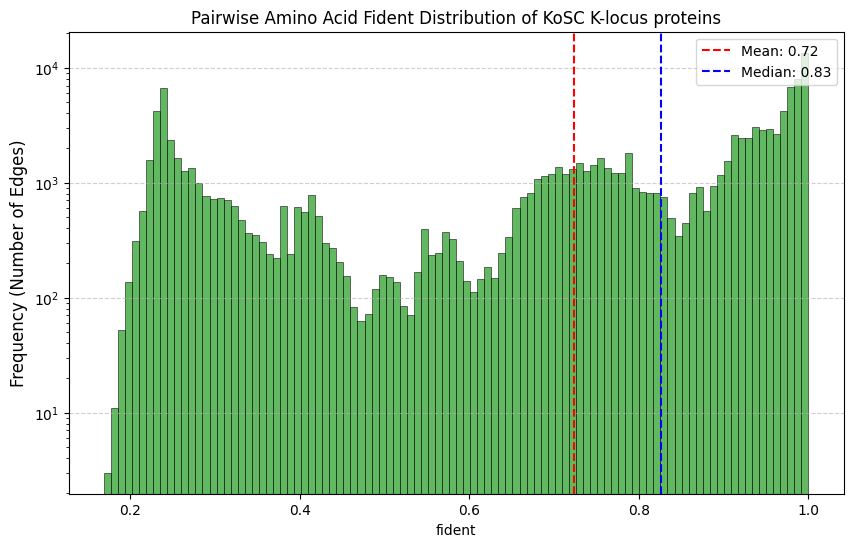

<Figure size 640x480 with 0 Axes>

In [53]:
%matplotlib inline
score_type = 'fident'
plt, ax = plot_score_distribution(aa_pw[score_type])
ax.set_xlabel(score_type)
ax.set_title(f'Pairwise Amino Acid {score_type.capitalize()} Distribution of KoSC K-locus proteins')
plt.show()
plt.tight_layout()

Median is 0.8, similar to KpSC (0.825)!

#### Get connected components

We will use the hard floor of `0.825` set by Kelly, but our median is slightly higher.

In [54]:
ids, matrix = build_matrix(aa_pw['query'], aa_pw['target'], aa_pw['fident'])
matrix.data[matrix.data < 0.825] = 0  # Hard limit set by Kelly
matrix.eliminate_zeros()
cc = pd.DataFrame({'Query': ids, 'CC': connected_components(matrix)[1]}).set_index('Query')
cc['CC_size'] = cc['CC'].map(cc['CC'].value_counts())

#### View the largest clusters

### Naive Clustering

#### Normalise the bit score

Raw bit scores are length-dependent.
A bit score of 500 might represent a perfect match for a small 100-amino-acid protein, but a very poor, fragmented match for a 2,000-amino-acid multi-domain protein.
If you we dealing with a diverse set of gene lengths, normalizing the bit score provides a truer reflection of biological identity.
The formula scales the score to a value between $0$ and $1$:$$\text{Normalized Score} = \frac{S_{A,B}}{\max(S_{A,A}, S_{B,B})}$$Where $S_{A,B}$ is the bit score of the alignment, and $S_{A,A}$ is the self-alignment bit score of the query.

In [55]:
# Extract the "Self-Score" for every unique protein
# A protein's max bitscore in an all-vs-all search is its alignment to itself.
self_scores = aa_pw[aa_pw['query'] == aa_pw['target']].set_index('query')['bits'].to_dict()
# # Vectorized Normalization, Map the self-scores back to the dataframe for fast math
aa_pw['q_self_bits'] = aa_pw['query'].map(self_scores)
aa_pw['t_self_bits'] = aa_pw['target'].map(self_scores)
# Calculate the denominator: max(S_A,A , S_B,B)
# We use np.maximum for fast element-wise comparison between the two columns
aa_pw['max_self_bits'] = np.maximum(aa_pw['q_self_bits'], aa_pw['t_self_bits'])
# Calculate the final normalized structural weight
aa_pw['norm_bits'] = aa_pw['bits'] / aa_pw['max_self_bits']

#### Plot distribution

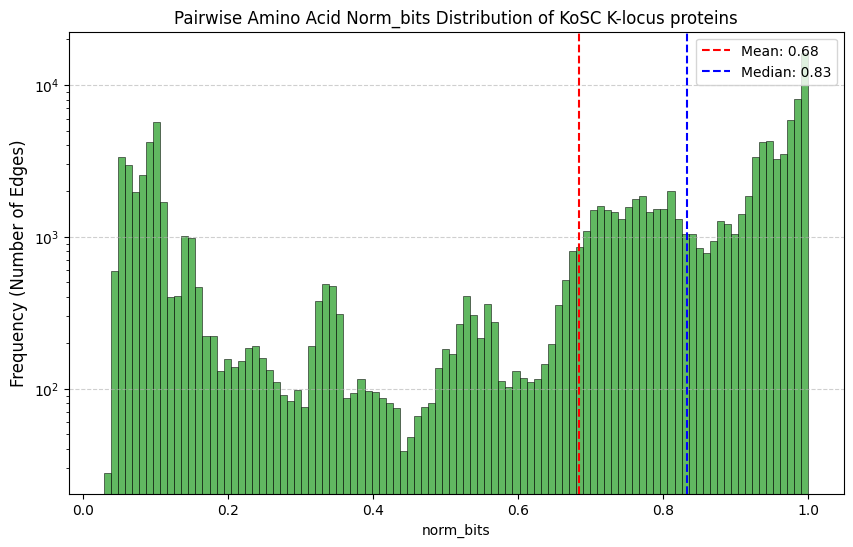

<Figure size 640x480 with 0 Axes>

In [56]:
%matplotlib inline
score_type = 'norm_bits'
plt, ax = plot_score_distribution(aa_pw[score_type])
ax.set_xlabel(score_type)
ax.set_title(f'Pairwise Amino Acid {score_type.capitalize()} Distribution of KoSC K-locus proteins')
plt.show()
plt.tight_layout()

#### Build matrix

#### Reduce dimensions

By enforcing a KNN graph (e.g., $K=10$), we cap the maximum degree of any single protein, forcing the graph topology to rely on local neighborhood similarities rather than absolute global weights.

In [57]:
ids, matrix = build_matrix(aa_pw['query'], aa_pw['target'], aa_pw['norm_bits'])
matrix.data[matrix.data < 0.2] = 0
matrix.eliminate_zeros()
knn = build_knn_graph(matrix, k=5)
knn_norm = normalize(matrix, norm='l2', axis=1)
snn = matrix.dot(matrix.T)
snn.eliminate_zeros()

In [58]:
lc = pd.DataFrame({'Query': ids, 'LC': Leiden(resolution=0.8).fit_predict(snn)}).set_index('Query')
lc['LC_size'] = lc['LC'].map(lc['LC'].value_counts())

## Further analysis

### Join all results

In [59]:
kosc_data = kosc_info.join(rbh).join(pfam).join(pgap).join(wzy).join(cc).join(lc)

### Glycosyl transferase (GTR) identification

In [80]:
pfam_gtr_mask = kosc_data['PfamA_Description'].str.contains('glyco', case=False) & kosc_data['PfamA_Description'].str.contains('trans', case=False)
pgap_gtr_mask = kosc_data['PGAP_Description'].str.contains('glyco', case=False) & kosc_data['PGAP_Description'].str.contains('trans', case=False)
print(f"Pfam GTRs: {pfam_gtr_mask.sum()}\n"
      f"PGAP GTRs: {pgap_gtr_mask.sum()}")

Pfam GTRs: 340
PGAP GTRs: 178


Pfam HMMs identified more GTRs - apply that mask

In [81]:
kosc_gtrs = kosc_data[pfam_gtr_mask]

Let's get the clusters of our known GTRs and see if we missed any.

In [82]:
gtr_cc = set(kosc_gtrs['CC'])
gtr_lc = set(kosc_gtrs['LC'])
cc_gtr_mask = kosc_data['CC'].isin(gtr_cc)
lc_gtr_mask = kosc_data['LC'].isin(gtr_lc)
print(f"Connected component GTRs: {cc_gtr_mask.sum()}\n\t- distinct={len(gtr_cc)}\n"
      f"Leiden cluster GTRs {lc_gtr_mask.sum()}\n\t- distinct={len(gtr_lc)}\n")

Connected component GTRs: 340
	- distinct=270
Leiden cluster GTRs 360
	- distinct=68



All members of each GTR connected component cluster have been annotated, wheras we get 20 more GTR Leiden cluster members that are not. Let's check them out.

In [85]:
kosc_data[(lc_gtr_mask) & ~(pfam_gtr_mask)]

,Locus_tag,Locus,Position,Gene_name,Length,KpSC_RBH,KpSC_RBH_fident,KpSC_RBH_Locus,KpSC_RBH_Position,KpSC_RBH_Gene_name,...,PGAP_Best,PGAP_Bitscore,PGAP_Description,Wzy_Best,Wzy_Bitscore,Wzy_Description,CC,CC_size,LC,LC_size
Query,,,,,,,,,,,,,,,,,,,,,
KL2_16,KL2_00016,KL2,16,No gene name,278,NaN,NaN,NaN,NaN,NaN,...,PgaC_IcaA,13.5,"JCVI: poly-beta-1,6-N-acetyl-D-glucosamine syn...",NaN,NaN,NaN,149,1,16,28
KL5_15_wcuS,KL5_00015,KL5,15,wcuS,285,KL80_15_gtr291,0.760,KL80,15,gtr291,...,PgaC_IcaA,10.2,"JCVI: poly-beta-1,6-N-acetyl-D-glucosamine syn...",NaN,NaN,NaN,99,1,16,28
KL10_10,KL10_00010,KL10,10,No gene name,284,KL152_10_gtr499,0.985,KL152,10,gtr499,...,PgaC_IcaA,15.1,"JCVI: poly-beta-1,6-N-acetyl-D-glucosamine syn...",NaN,NaN,NaN,151,1,16,28
KL18_12_wcqM,KL18_00012,KL18,12,wcqM,286,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,207,2,16,28
KL19_09_wcqM,KL19_00009,KL19,9,wcqM,282,KL181_09_gtr602,0.989,KL181,09,gtr602,...,rhamnosyltran,15.3,JCVI: rhamnosyltransferase,NaN,NaN,NaN,678,1,16,28
KL20_10,KL20_00010,KL20,10,No gene name,282,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,516,1,16,28
KL24_15_wcqP,KL24_00015,KL24,15,wcqP,297,KL101_13_gtr302,0.477,KL101,13,gtr302,...,NaN,NaN,NaN,NaN,NaN,NaN,252,2,16,28
KL30_12_wcuT,KL30_00012,KL30,12,wcuT,283,KL47_12_gtr184,0.812,KL47,12,gtr184,...,rhamnosyltran,26.9,JCVI: rhamnosyltransferase,NaN,NaN,NaN,16,1,16,28
KL35_12_wcqM,KL35_00013,KL35,12,wcqM,286,KL81_12_gtr295,0.413,KL81,12,gtr295,...,rhamnosyltran,18.3,JCVI: rhamnosyltransferase,NaN,NaN,NaN,207,2,16,28


Yep, they look like legit GTRs to me! Let's use the lc_gtr_mask to pull out the 360 GTRs.

In [89]:
kosc_gtrs = kosc_data[lc_gtr_mask]
kosc_data['Is_Glycosyl_transferase'] = lc_gtr_mask
print(f"{len(set(kosc_gtrs['CC']))} distinct GTR connected component clusters")

288 distinct GTR connected component clusters


## WcaJ / WbaP Quantification

In [97]:
init_gtr_mask = kosc_data['PfamA_Best'] == 'Bac_transf'
print(f'{init_gtr_mask.sum()} Init GTRs found')

88 Init GTRs found


Great! 88 loci all have an init GTR! But how do we distinguish them?

In [ ]:
init_gtrs = kosc_data[init_gtr_mask]
print(f'')
set(init_gtrs['CC'])

In [105]:
init_gtrs.value_counts(['LC', 'PGAP_Best', 'Gene_name'])

LC  PGAP_Best   Gene_name
8   PRK15204.1  wbaP         58
                wcaJ         19
25  PRK10124.1  wcaJ         11
Name: count, dtype: int64

Hahaha so our leiden clusters perfectly align to the PGAP HMM hits AND they form 2 distinct clusters!
LC8 (PRK15204.1) == WbaP and LC25 (PRK10124.1) == WcaJ.

## Per locus summary

In [118]:
print(
    kosc_data
    .groupby('Locus')
    .agg(
        N_genes=('Locus', 'size'),
        Matching_KpSC_genes=('KpSC_RBH', 'count'),
        Wzy_copies=('Wzy_Best', 'count'),
        Distinct_GTRs=('Is_Glycosyl_transferase', 'sum'),
        WcaJ_copies=('LC', lambda i: sum(i == 25)),
        WbaP_copies=('LC', lambda i: sum(i == 8))
    )
    .rename(columns=lambda x: x.replace('_', ' '))
    .to_markdown()
)

| Locus   |   N genes |   Matching KpSC genes |   Wzy copies |   Distinct GTRs |   WcaJ copies |   WbaP copies |
|:--------|----------:|----------------------:|-------------:|----------------:|--------------:|--------------:|
| KL1     |        22 |                     4 |            1 |               4 |             0 |             1 |
| KL10    |        21 |                    17 |            1 |               4 |             0 |             1 |
| KL11    |        17 |                    15 |            1 |               4 |             0 |             1 |
| KL12    |        20 |                    10 |            1 |               3 |             0 |             1 |
| KL13    |        21 |                    10 |            1 |               4 |             0 |             1 |
| KL14    |        22 |                    18 |            1 |               4 |             0 |             1 |
| KL15    |        23 |                     5 |            1 |               6 |             0 |

## Save data

In [112]:
kosc_data.to_csv('kosc_data.csv')